# Error Analysis

The error analysis is divided into three parts, the first of which examines the overlap between BM25 and dense search. Its objective is to determine the extent to which BM25 and dense search retrieve the same products, and what occurs within RRF when the same products are not found.

The second part identifies the specific stage at which the pipeline fails.

The third part covers the manual classification of top-1 errors.


Manual classification of the top 1 results that failed

Provide: Error Categories in the Report

BM25: "6-koloruuvi" vs, "kuusiokoloruuvi"

In [2]:
# libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## BM25 and Dense overlapping

The Cross-Encoder log was not run in the 7th notebook, so we will run it here.

In [3]:
# dev set
dev = pd.read_csv('../data/clean/test_set_dev.csv', dtype={'gold_product_number': str})
dev_queries = dev.groupby('clean_query').agg({
    'gold_product_number': lambda x: set(str(p) for p in x),
    'product_label': 'first',
    'area_name': 'first'
}).reset_index()

In [4]:
# BM25 and dense search results
bm25_df = pd.read_csv('../data/clean/bm25_stem_top100_dev.csv', dtype={'product_number': str})
dense_df = pd.read_csv('../data/clean/dense_e5_top100_dev.csv', dtype={'product_number': str})

bm25_top20 = bm25_df[bm25_df['rank'] <= 20]
dense_top20 = dense_df[dense_df['rank'] <= 20]

In [ ]:
# overlap analysis
overlap_records = []

for q in dev_queries['clean_query']:
    bm25_prods = set(bm25_top20[bm25_top20['clean_query'] == q]['product_number'])
    dense_prods = set(dense_top20[dense_top20['clean_query'] == q]['product_number'])
    
    common = bm25_prods & dense_prods # AND
    union = bm25_prods | dense_prods # OR
    
    overlap_records.append({
        'clean_query': q,
        'common_count': len(common),
        'jaccard_similarity': len(common) / len(union) if union else 0.0,
        'zero_overlap': len(common) == 0
    })

df_overlap = pd.DataFrame(overlap_records)

print(f"Average common products in top-20: {df_overlap['common_count'].mean():.2f}")
print(f"Jaccard Similarity (Average): {df_overlap['jaccard_similarity'].mean():.3f}")
print(f"Queries with 0 overlapping products in dev set: {df_overlap['zero_overlap'].sum()} ({df_overlap['zero_overlap'].mean()*100:.1f} %)")

Average common products in top-20: 2.91
Jaccard Similarity (Average): 0.089
Queries with 0 overlapping products in dev set: 33 (24.3 %)


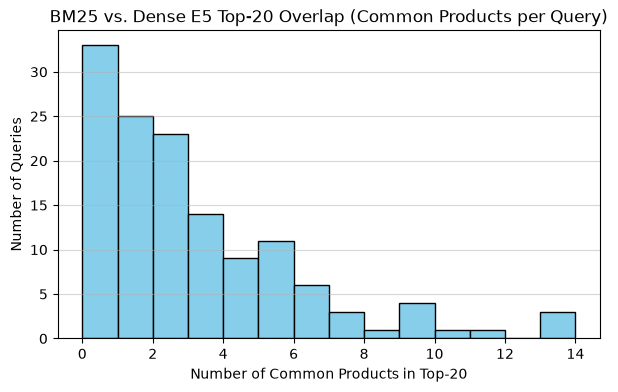

In [9]:
plt.figure(figsize=(7, 4))
plt.hist(df_overlap['common_count'], bins=range(0, 15), edgecolor='black', color='skyblue')
plt.title('BM25 vs. Dense E5 Top-20 Overlap (Common Products per Query)')
plt.xlabel('Number of Common Products in Top-20')
plt.ylabel('Number of Queries')
plt.grid(axis='y', alpha=0.5)
plt.show()

* Out of 20 products, on average only 2.9 are the same.
* Jaccard Similarity (0-1): 0.089 , BM25 and Dense mostly find different products.
    * BM25 finds very precise codes and measurements.
    * Dense searches at a more general conceptual level, but loses the numbers and sizes.
* In 33 queries (24.3%), BM25 and Dense did not share any common products.
    * Impact on the RRF:
        * RRF works best when the same product appears on both lists, in which case it receives double points.
        * When the score is zero, both receive the same points, resulting in a tie. In such cases, RRF interleaves the items by alternating between them; however, since BM25 is added to the list first in the code, BM25 wins the tie. RRF doesn't know who has more correct guesses.

This may explain why the Cross-Encoder improves the result so much. It acts as a referee.

"6-koloruuvi" vs, "kuusiokoloruuvi"

There are two different way to label "kuusiokoloruuvi".

"6" = "kuusio"

-> BM25 does not find differences in between top 5 products.

(test function in retreivers)

The system only recognizes specific product names, but it can see the hierarchy above that.

BM25 is blind to synonyms, but it is fast.

Reminder for error analysis: for the query “kuusiokoloruuvi din7984 a4 m8x40”, the BM25 and dense top 20 lists had no products in common, so RRF only interleaved them and BM25 won every tie because its results are added first. Check how often the lists do not overlap on the dev set, because in those cases hybrid Hit@1 simply equals BM25 Hit@1. The query also shows an abbreviation problem: the catalog writes “6-koloruuvi”, so the correct product gets zero points for “kuusiokoloruuvi” while products that use the full word in their description get extra points.

## Pipeline funnel

Where pipeline fails..

In [12]:
# load all results of the pipeline

dev = pd.read_csv('../data/clean/test_set_dev.csv', dtype={'gold_product_number': str})
dev_queries = dev.groupby('clean_query').agg({
    'gold_product_number': lambda x: set(str(p) for p in x),
    'product_label': 'first',
    'area_name': 'first'
}).reset_index()

bm25_top20 = pd.read_csv('../data/clean/bm25_stem_top100_dev.csv', dtype={'product_number': str})
bm25_top20 = bm25_top20[bm25_top20['rank'] <= 20]
dense_top20 = pd.read_csv('../data/clean/dense_e5_top100_dev.csv', dtype={'product_number': str})
dense_top20 = dense_top20[dense_top20['rank'] <= 20]
hybrid_top20 = pd.read_csv('../data/clean/hybrid_rrf_top20_dev.csv', dtype={'product_number': str})
reranked_top20 = pd.read_csv('../data/clean/reranked_top20_dev.csv', dtype={'product_number': str})
llm_log = pd.read_csv('../data/clean/rag_selection_log_qwen3.5_9b.csv', dtype={'chosen_code': str})

In [16]:
# trace the pipeline for each query
funnel_records = []

for _, row in dev_queries.iterrows():
    q = row['clean_query']
    gold = row['gold_product_number']
    
    b20 = set(bm25_top20[bm25_top20['clean_query'] == q]['product_number'])
    d20 = set(dense_top20[dense_top20['clean_query'] == q]['product_number'])
    h20 = set(hybrid_top20[hybrid_top20['clean_query'] == q]['product_number'])

    ce_rank1 = reranked_top20[(reranked_top20['clean_query'] == q) & (reranked_top20['rank'] == 1)]
    ce_hit1 = any(p in gold for p in ce_rank1['product_number']) if not ce_rank1.empty else False

    llm_row = llm_log[llm_log['clean_query'] == q]
    llm_hit1 = llm_row['is_hit'].values[0] if not llm_row.empty else False

    funnel_records.append({
        'clean_query': q,
        'area_name': row['area_name'],
        'gold_label': row['product_label'],
        'in_bm25_top20': any(p in gold for p in b20),
        'in_dense_top20': any(p in gold for p in d20),
        'in_hybrid_top20': any(p in gold for p in h20),
        'ce_hit1': ce_hit1,
        'llm_hit1': llm_hit1
    })

df_funnel = pd.DataFrame(funnel_records)

In [17]:
# funnel statistics
n_total = len(df_funnel)
retrieved_count = df_funnel['in_hybrid_top20'].sum()
retrieval_fail = n_total - retrieved_count

ce_hits = df_funnel['ce_hit1'].sum()
ce_rank_fail = retrieved_count - ce_hits

llm_hits = df_funnel['llm_hit1'].sum()
llm_fail = retrieved_count - llm_hits

In [23]:
print(f"Total queries: {n_total} (100 %)")
print(f"1. Search Stage: {retrieved_count} ({retrieved_count/n_total*100:.1f} %)")
print(f"   -> Failed in Search Stage (Retrieval): {retrieval_fail} ({retrieval_fail/n_total*100:.1f} %)")

print(f"2. Cross-Encoder Hit@1:  {ce_hits}  ({ce_hits/n_total*100:.1f} %)")
print(f"   -> Failed in Reranking Stage (Ranking): {ce_rank_fail} ({ce_rank_fail/n_total*100:.1f} %)")

print(f"3. LLM Selection Hit@1:  {llm_hits}  ({llm_hits/n_total*100:.1f} %)")
print(f"   -> Failed in LLM Selection Stage (Selection): {llm_fail} ({llm_fail/n_total*100:.1f} %)")

Total queries: 136 (100 %)
1. Search Stage: 81 (59.6 %)
   -> Failed in Search Stage (Retrieval): 55 (40.4 %)
2. Cross-Encoder Hit@1:  45  (33.1 %)
   -> Failed in Reranking Stage (Ranking): 36 (26.5 %)
3. LLM Selection Hit@1:  31  (22.8 %)
   -> Failed in LLM Selection Stage (Selection): 50 (36.8 %)


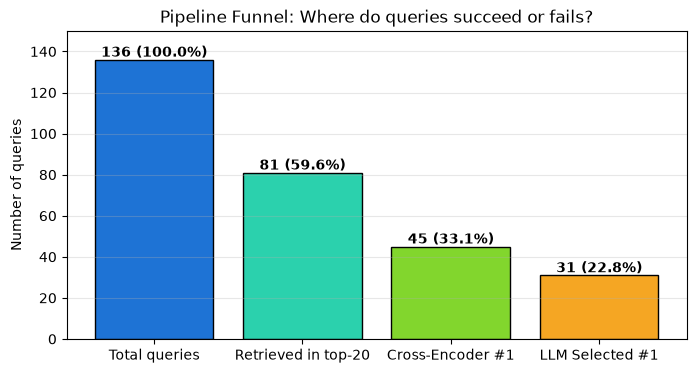

In [22]:
stages = ['Total queries', 'Retrieved in top-20', 'Cross-Encoder #1', 'LLM Selected #1']
counts = [n_total, retrieved_count, ce_hits, llm_hits]
colors = ["#1e73d5", "#2bd1ad", "#82d62d", '#f5a623']

plt.figure(figsize=(8, 4))
bars = plt.bar(stages, counts, color=colors, edgecolor='black')
plt.title('Pipeline Funnel: Where do queries succeed or fails?')
plt.ylabel('Number of queries')
plt.grid(axis='y', alpha=0.3)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval} ({yval/n_total*100:.1f}%)", ha='center', fontweight='bold')
plt.ylim(0, 150)
plt.show()

* 55 queries failed before any Reranker or LLM could even touch them.
    * The main area for improvement is enhancing the initial search phase.

* The actual performance of the Cross-Encoder was 55.6%.
    * It placed the correct product first 45 times out of 81.
    * In only 36 of the queries (26.5% of the total), the correct product ranked between 2-20nd.

* The LLM missed 14 matches that the Cross-Encoder found.
    * This is directly explained by previously observed hallucinations (16.2%) and overly cautious "none" responses (16.9%).

## Manual error categorization

## Recommendations

### Multi-Stage Reranking